In [20]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

converged at 95989


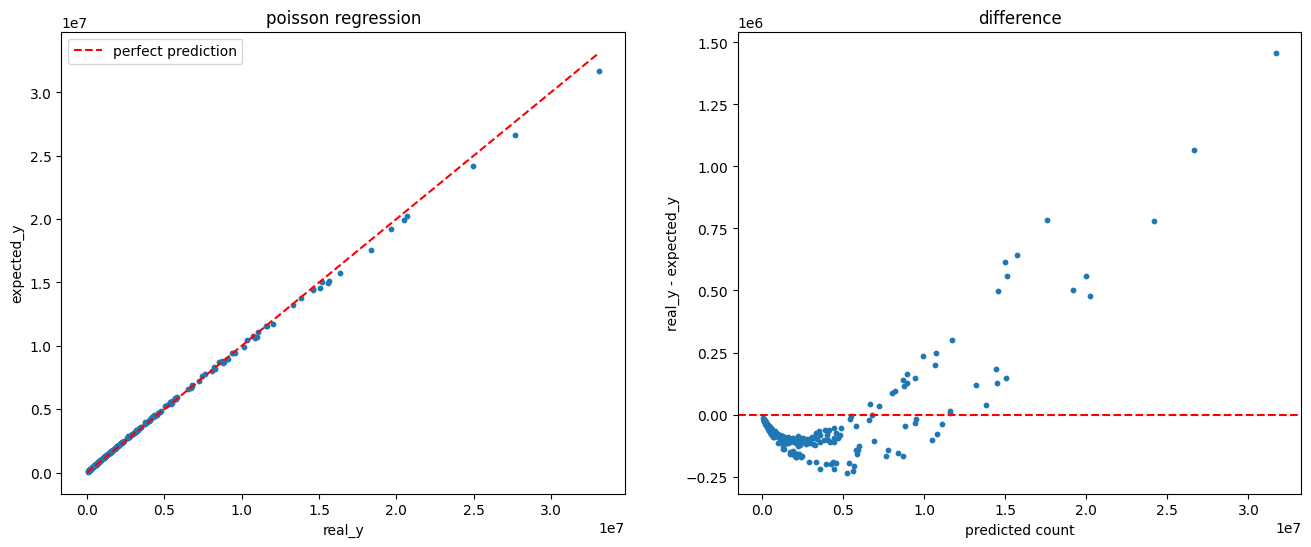

mean difference: -33426.46935215718
mean absolute difference: 117596.32641729675
[11.52272871 11.01839115  1.92352875  4.19284107]


In [39]:
train_data = pd.read_csv('../ps1/ds4_train.csv')
validation_data = pd.read_csv('../ps1/ds4_valid.csv')

features = ['x_1', 'x_2', 'x_3', 'x_4']
OUTPUT_PATH = '/home/sssclass/Desktop/project/cs229/problem_set1/output' 
ouput_file = 'problem3_possion_regresion'

e = 10**-5

def gradient_ascent(alpha, max_iter=200000):
    X = train_data[features].values
    y = train_data['y'].values
    m = len(y)
    w = np.zeros(X.shape[1])
    w[:2] = np.log(y.mean())             
    for i in range(max_iter):
        w_new = w + alpha * (X.T @ (y - np.exp(X @ w))) / m
        if not np.isfinite(w_new).all():
            print('diverged: lower alpha'); return w
        if np.linalg.norm(w_new - w) < e:
            print('converged at', i); return w_new
        w = w_new
    print('did NOT converge'); return w


def output_prdict(w):
    y_hat = np.exp(validation_data[features].dot(w))
    y_hat.to_csv(f'{OUTPUT_PATH}/{ouput_file}.txt', index=False, header=False)
    return y_hat


def output_plot_2d(w):
    y_hat = output_prdict(w).values          
    y_true = validation_data['y'].values     
    diff = y_true - y_hat                    

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].scatter(y_true, y_hat, s=10)
    lim = [0, max(y_true.max(), y_hat.max())]
    axes[0].plot(lim, lim, 'r--', label='perfect prediction')
    axes[0].set_xlabel('real_y')
    axes[0].set_ylabel('expected_y')
    axes[0].set_title('poisson regression')
    axes[0].legend()

    
    axes[1].scatter(y_hat, diff, s=10)
    axes[1].axhline(0, color='r', linestyle='--')
    axes[1].set_xlabel('predicted count')
    axes[1].set_ylabel('real_y - expected_y')
    axes[1].set_title('difference')

    fig.savefig(f'{OUTPUT_PATH}/{ouput_file}.png', dpi=300, bbox_inches='tight')
    plt.show()

    print('mean difference:', diff.mean())
    print('mean absolute difference:', np.abs(diff).mean())

w = gradient_ascent(5*1e-10)
output_plot_2d(w)
print(w)